# DevBugger comparative analysis
Run the cells in order from a clone of this repository using the versions in requirements.txt. The notebook reads devbugger_dataset_800.csv from the same folder. In Colab, upload the CSV to the working directory first. Model scores use fixed splits and seeds. Wall-clock timings depend on the machine.

In [1]:
from pathlib import Path
from time import perf_counter
from tempfile import TemporaryDirectory
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                            f1_score, mean_absolute_error, mean_squared_error, r2_score,
                            precision_score, recall_score, root_mean_squared_error)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display

SEED = 42
df = pd.read_csv("devbugger_dataset_800.csv")
assert len(df) == 800 and df.row_id.is_unique and df.url.is_unique
assert df[["Bug_Type", "source", "resolution_hours"]].notna().all().all()
assert (df.resolution_hours >= 0).all()
print(platform.python_version(), sklearn.__version__, np.__version__, pd.__version__)
display(pd.crosstab(df.Bug_Type, df.source, margins=True))
display(df.resolution_hours.describe())
print("Skew:", df.resolution_hours.skew(), "Above 365 days:", (df.resolution_hours > 8760).sum())
display(df.groupby("source").resolution_hours.median())
print("Unique GitHub repositories:", df.repository.nunique())
print("Label differences:", df.Bug_Type.ne(df.candidate_Bug_Type).sum())
print("Bodies with different full lengths:", df.body.str.len().ne(df.body_len_chars).sum())
display(df.content_license.value_counts())

3.13.17 1.9.1 2.5.5 3.1.1
Skew: 4.690758210681624 Above 365 days: 97
Unique GitHub repositories: 58
Label differences: 45
Bodies with different full lengths: 128


source,GitHub,Stack Overflow,All
Bug_Type,,,
API_Error,110,50,160
Authentication,112,50,162
CORS_Error,117,50,167
Database_Connection,105,50,155
State_Management,106,50,156
All,550,250,800


,resolution_hours
count,800.000000
mean,3287.323687
std,8811.560799
min,0.016900
25%,1.574225
50%,35.455400
75%,1601.471300
max,83830.928100


,resolution_hours
source,
GitHub,175.6796
Stack Overflow,1.1089


,count
content_license,
CC BY-SA 4.0,183
CC BY-SA 3.0,67


## Choose the inputs and reserve the test reports
Combine the title and body into one text field. Use the stored full-text counts. Only the known-category regression experiment also receives the recorded bug type. Stratifying by source and category keeps both represented in every partition.

In [2]:
counts = ["title_len_words", "body_len_chars", "n_code_blocks", "n_urls"]
flags = ["has_stack_trace", "has_error_code", "has_http_status", "has_version_info", "has_repro_steps"]
x = df[["source", *counts, *flags]].copy()
x["text"] = (df.report_title.fillna("") + " " + df.body.fillna("")).str.replace(
    r"https?://\S+|(?:[A-Za-z]:\\|/home/|/Users/)\S+|:\d+:\d+\b", " ", regex=True)
x_reg = x.assign(Bug_Type=df.Bug_Type)
strata = df.source + "|" + df.Bug_Type
train, test = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=strata)
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(train, strata.iloc[train]))
classes = sorted(df.Bug_Type.unique())
print("Rows in train and test:", len(train), len(test))
print("GitHub repositories in both:", len(set(df.repository.iloc[train].dropna()) & set(df.repository.iloc[test].dropna())))

Rows in train and test: 640 160
GitHub repositories in both: 35


## Preprocessing and model grids
Each tunable model gets four configurations and the same five folds. Ordinary least squares and the two constant comparators have fixed settings. All learned encoders, vocabulary and scalers fit inside the folds. Regression is trained on log(1 + hours). Its inverse returns nonnegative hours for scoring.

In [3]:
def preprocessing(regression):
    cat = ["source", "Bug_Type"] if regression else ["source"]
    return ColumnTransformer([
        ("text", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000,
                                 sublinear_tf=True), "text"),
        ("categorical", make_pipeline(SimpleImputer(strategy="constant", fill_value="Unknown"),
                                      OneHotEncoder(handle_unknown="ignore")), cat),
        ("counts", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), counts),
        ("flags", SimpleImputer(strategy="most_frequent"), flags),
    ], sparse_threshold=1.0)

def hours_from_log(values):
    return np.maximum(0.0, np.expm1(values))

classifier_specs = [
    ("Logistic", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED), {"C":[0.5, 1, 4, 16]}),
    ("KNN", KNeighborsClassifier(metric="cosine", algorithm="brute"), {"n_neighbors":[5, 15], "weights":["uniform","distance"]}),
    ("Tree", DecisionTreeClassifier(class_weight="balanced", random_state=SEED), {"max_depth":[10,None],"min_samples_split":[2,8]}),
    ("Forest", RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=1), {"n_estimators":[60,120],"max_depth":[20,None]}),
    ("SVM", SVC(class_weight="balanced",random_state=SEED), {"C":[1,10],"kernel":["linear","rbf"]}),
]
regressor_specs = [
    ("Linear", LinearRegression(), {}),
    ("KNN", KNeighborsRegressor(metric="cosine", algorithm="brute"), {"n_neighbors":[5,15],"weights":["uniform","distance"]}),
    ("Tree", DecisionTreeRegressor(random_state=SEED), {"max_depth":[5,None],"min_samples_leaf":[2,8]}),
    ("Forest", RandomForestRegressor(random_state=SEED,n_jobs=1,max_features=0.15), {"n_estimators":[60,120],"max_depth":[8,None]}),
    ("SVR", SVR(kernel="rbf"), {"C":[1,10],"epsilon":[0.1,0.5]}),
]

## Tune using training data
Weighted F1 selects classifiers. RMSE in original hours selects regressors. Cache fold-specific training transformations during grid search. The selected models for both tasks are fixed before the next cell opens the holdout.

In [4]:
def tune(specs, regression):
    features, target = (x_reg, df.resolution_hours) if regression else (x, df.Bug_Type)
    results = {}
    with TemporaryDirectory() as cache:
        for name, model, grid in specs:
            estimator = (TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=hours_from_log)
                         if regression else model)
            pipe = Pipeline([("features",preprocessing(regression)),("model",estimator)], memory=cache)
            prefix = "model__regressor__" if regression else "model__"
            search = GridSearchCV(pipe, {prefix+k:v for k,v in grid.items()}, cv=cv, refit=False,
                                  scoring="neg_root_mean_squared_error" if regression else "f1_weighted",
                                  n_jobs=1, error_score="raise")
            search.fit(features.iloc[train], target.iloc[train])
            i = search.best_index_
            final = clone(pipe).set_params(memory=None, **search.best_params_)
            start = perf_counter()
            final.fit(features.iloc[train], target.iloc[train])
            fit_sec = perf_counter() - start
            results[name] = dict(estimator=final, cv=abs(search.best_score_),
                                 sd=search.cv_results_["std_test_score"][i], fit=fit_sec,
                                 params={k.removeprefix(prefix):v for k,v in search.best_params_.items()})
    return results

with threadpool_limits(limits=1):
    classifiers = tune(classifier_specs, False)
    regressors = tune(regressor_specs, True)
best_c = max(classifiers, key=lambda name: classifiers[name]["cv"])
best_r = min(regressors, key=lambda name: regressors[name]["cv"])
print("Selected by CV:", best_c, best_r)

Selected by CV: SVM Tree


## Final evaluation
Fit time includes preprocessing and the final estimator, excluding grid search. Prediction time is the median of five passes over the same 160 rows. Compute accuracy, weighted precision/recall/F1, macro F1 and per-class reports. Regression errors use hours (MSE uses squared hours).

In [5]:
def timed_predict(estimator, test_features):
    times = []
    for _ in range(5):
        start = perf_counter()
        pred = estimator.predict(test_features)
        times.append(perf_counter()-start)
    return pred, float(np.median(times))

def evaluate(models, regression):
    features,target = (x_reg, df.resolution_hours) if regression else (x, df.Bug_Type)
    rows, predictions = [], {}
    for name, info in models.items():
        model = info["estimator"]
        train_pred = model.predict(features.iloc[train])
        pred, seconds = timed_predict(model, features.iloc[test])
        predictions[name] = pred
        obs = target.iloc[test]
        if regression:
            metrics = dict(train=root_mean_squared_error(target.iloc[train],train_pred),
                           mae=mean_absolute_error(obs,pred),mse=mean_squared_error(obs,pred),
                           rmse=root_mean_squared_error(obs,pred),r2=r2_score(obs,pred))
        else:
            metrics = dict(train=f1_score(target.iloc[train],train_pred,average="weighted"),
                           accuracy=accuracy_score(obs,pred),precision=precision_score(obs,pred,average="weighted",zero_division=0),
                           recall=recall_score(obs,pred,average="weighted",zero_division=0),
                           f1=f1_score(obs,pred,average="weighted"),macro=f1_score(obs,pred,average="macro"))
        rows.append(dict(name=name,**metrics,cv=info["cv"],sd=info["sd"],fit=info["fit"],predict=seconds))
    return pd.DataFrame(rows).set_index("name"), predictions

with threadpool_limits(limits=1):
    ctab, cpred = evaluate(classifiers,False)
    rtab, rpred = evaluate(regressors,True)
for table, models in [(ctab,classifiers),(rtab,regressors)]:
    display(table.round(4))
    print({name:v["params"] for name,v in models.items()})
for name, pred in cpred.items():
    print(name)
    print(classification_report(df.Bug_Type.iloc[test], pred, labels=classes, digits=3))
    display(pd.DataFrame(confusion_matrix(df.Bug_Type.iloc[test],pred,labels=classes),index=classes,columns=classes))

{'Logistic': {'C': 16}, 'KNN': {'n_neighbors': 5, 'weights': 'distance'}, 'Tree': {'max_depth': 10, 'min_samples_split': 8}, 'Forest': {'max_depth': None, 'n_estimators': 120}, 'SVM': {'C': 1, 'kernel': 'linear'}}
{'Linear': {}, 'KNN': {'n_neighbors': 5, 'weights': 'distance'}, 'Tree': {'max_depth': 5, 'min_samples_leaf': 8}, 'Forest': {'max_depth': None, 'n_estimators': 60}, 'SVR': {'C': 10, 'epsilon': 0.1}}
Logistic
                     precision    recall  f1-score   support

          API_Error      0.812     0.812     0.812        32
     Authentication      0.935     0.906     0.921        32
         CORS_Error      0.882     0.882     0.882        34
Database_Connection      0.939     1.000     0.969        31
   State_Management      1.000     0.968     0.984        31

           accuracy                          0.912       160
          macro avg      0.914     0.914     0.914       160
       weighted avg      0.913     0.912     0.912       160

KNN
                     p

,train,accuracy,precision,recall,f1,macro,cv,sd,fit,predict
name,,,,,,,,,,
Logistic,1.0000,0.9125,0.9129,0.9125,0.9124,0.9136,0.9102,0.0167,1.5842,0.0869
KNN,1.0000,0.6000,0.5944,0.6000,0.5873,0.5869,0.5532,0.0281,1.2447,0.1021
Tree,0.9414,0.7812,0.8102,0.7812,0.7851,0.7865,0.8100,0.0265,1.3473,0.0807
Forest,1.0000,0.8875,0.8922,0.8875,0.8876,0.8890,0.9134,0.0090,2.0402,0.1058
SVM,0.9969,0.9188,0.9223,0.9188,0.9199,0.9208,0.9222,0.0200,3.3324,0.2596


,train,mae,mse,rmse,r2,cv,sd,fit,predict
name,,,,,,,,,
Linear,3.4348,3580.3390,7.264943e+07,8523.4632,-0.0261,9050.3701,2219.9632,0.7346,0.1030
KNN,0.0000,3526.9037,7.737321e+07,8796.2045,-0.0928,9013.2102,2316.2592,0.8256,0.1156
Tree,8644.2689,3654.4439,7.910643e+07,8894.1795,-0.1173,8942.6762,2245.4916,0.5673,0.0816
Forest,7726.0100,3548.1638,7.982641e+07,8934.5629,-0.1275,9022.8273,2341.3082,6.6432,0.1259
SVR,7822.0052,3590.8697,7.988826e+07,8938.0234,-0.1283,8949.8408,2338.1834,1.3891,0.2589


,API_Error,Authentication,CORS_Error,Database_Connection,State_Management
API_Error,26,2,3,1,0
Authentication,2,29,1,0,0
CORS_Error,3,0,30,1,0
Database_Connection,0,0,0,31,0
State_Management,1,0,0,0,30


,API_Error,Authentication,CORS_Error,Database_Connection,State_Management
API_Error,10,10,2,8,2
Authentication,4,15,4,3,6
CORS_Error,4,1,24,2,3
Database_Connection,0,2,2,23,4
State_Management,0,3,2,2,24


,API_Error,Authentication,CORS_Error,Database_Connection,State_Management
API_Error,26,0,4,0,2
Authentication,8,19,1,1,3
CORS_Error,9,0,25,0,0
Database_Connection,1,1,0,29,0
State_Management,3,2,0,0,26


,API_Error,Authentication,CORS_Error,Database_Connection,State_Management
API_Error,27,1,2,1,1
Authentication,2,26,2,1,1
CORS_Error,6,0,28,0,0
Database_Connection,1,0,0,30,0
State_Management,0,0,0,0,31


,API_Error,Authentication,CORS_Error,Database_Connection,State_Management
API_Error,27,2,2,1,0
Authentication,2,30,0,0,0
CORS_Error,4,0,30,0,0
Database_Connection,1,0,0,30,0
State_Management,1,0,0,0,30


In [6]:
obs = df.resolution_hours.iloc[test].to_numpy()
pred = rpred[best_r]
true_c = df.Bug_Type.iloc[test]
dummy_c = DummyClassifier(strategy="most_frequent").fit(x.iloc[train],df.Bug_Type.iloc[train]).predict(x.iloc[test])
dummy_r = DummyRegressor(strategy="mean").fit(x.iloc[train],df.resolution_hours.iloc[train]).predict(x.iloc[test])
def error_summary(actual, estimate):
    return {"MAE":mean_absolute_error(actual,estimate),"MSE":mean_squared_error(actual,estimate),
            "RMSE":root_mean_squared_error(actual,estimate),"R2":r2_score(actual,estimate)}
print("Most frequent class:", accuracy_score(true_c,dummy_c),f1_score(true_c,dummy_c,average="weighted"))
print("Training mean and baseline errors:", dummy_r[0],error_summary(obs,dummy_r))
deploy_x = x_reg.iloc[test].assign(Bug_Type=cpred[best_c])
deploy_pred = regressors[best_r]["estimator"].predict(deploy_x)
print("Predicted-category workflow:",error_summary(obs,deploy_pred))
for source in df.source.unique():
    sel = df.source.iloc[test].eq(source).to_numpy()
    print(source,sel.sum(),error_summary(obs[sel],pred[sel]))
display(df.groupby("Bug_Type").resolution_hours.median().sort_values())
details=df.iloc[test][["row_id","source","Bug_Type","report_title","resolution_hours"]].copy()
details["predicted_hours"]=pred
details["predicted_class"]=cpred[best_c]
details["absolute_error"]=abs(obs-pred)
display(details[details.Bug_Type.ne(details.predicted_class)])
display(details.nlargest(5,"absolute_error"))

Most frequent class: 0.2125 0.07448453608247421
Training mean and baseline errors: 3189.80221125 {'MAE': 4900.099634109375, 'MSE': 71039639.41318195, 'RMSE': 8428.501611388701, 'R2': -0.0033581164934006758}
Predicted-category workflow: {'MAE': 3654.4438760447265, 'MSE': 79106429.86461867, 'RMSE': 8894.179549830253, 'R2': -0.11729281183193874}
GitHub 110 {'MAE': 5214.24731717421, 'MSE': 114719889.5248585, 'RMSE': 10710.737113983263, 'R2': -0.21084333530756738}
Stack Overflow 50 {'MAE': 222.8763055598615, 'MSE': 756818.6120909944, 'RMSE': 869.9532240821884, 'R2': -0.05400159106987834}


,resolution_hours
Bug_Type,
State_Management,4.92070
Authentication,22.98905
API_Error,29.63915
CORS_Error,44.77610
Database_Connection,92.01140


,row_id,source,Bug_Type,report_title,resolution_hours,predicted_hours,predicted_class,absolute_error
508,316,GitHub,API_Error,On aws server side getting 404 not found error,27287.6411,1171.450118,CORS_Error,26116.190982
170,80,GitHub,Authentication,Impossible to catch the cookie client side with vercel when passport redirect,7.4325,1171.450118,API_Error,1164.017618
588,589,Stack Overflow,CORS_Error,Axios Error: No 'Access-Control-Allow-Origin' header is present on the requested resource,2133.0217,1.429213,API_Error,2131.592487
8,454,GitHub,CORS_Error,Error: Can't set headers after they are sent. CORS,28.2139,68.938719,API_Error,40.724819
783,784,Stack Overflow,Database_Connection,Mongoose buffering timed out when model is in a referenced project,141.8792,34.752212,API_Error,107.126988
374,38,GitHub,API_Error,Request sends Twice returns HTTP 500 Error,27022.7464,581.423773,CORS_Error,26441.322627
442,347,GitHub,CORS_Error,Error: Cross origin http://localhost forbidden,11256.5028,68.938719,API_Error,11187.564081
328,321,GitHub,CORS_Error,Error response missing CORS exposed headers,14109.3694,68.938719,API_Error,14040.430681
373,473,GitHub,State_Management,[3.0] TypePolicy Does Not Trigger Network Fetch on Cache Miss,283.3975,2630.962130,API_Error,2347.564630
362,155,GitHub,API_Error,Cannot send data using axios.post(),5.4839,68.938719,Authentication,63.454819


,row_id,source,Bug_Type,report_title,resolution_hours,predicted_hours,predicted_class,absolute_error
405,451,GitHub,CORS_Error,CORS pre-flight breaks socket.io behind load balancer,47745.5094,68.938719,CORS_Error,47676.570681
517,514,GitHub,Authentication,"Login fails if the ""username"" field contains ""+"" character",43948.3178,68.938719,Authentication,43879.379081
298,450,GitHub,API_Error,"Multer skips the request, when boundary contains an equal sign ""=""",41725.2981,68.938719,API_Error,41656.359381
301,279,GitHub,Database_Connection,Mongo Serverless,38015.1897,68.938719,Database_Connection,37946.250981
374,38,GitHub,API_Error,Request sends Twice returns HTTP 500 Error,27022.7464,581.423773,CORS_Error,26441.322627


## Figures
Rows of the confusion matrix are true categories. On the time plot, points below the diagonal mark underestimates. Both axes use the same log(1 + hours) display scale and show ticks in hours.

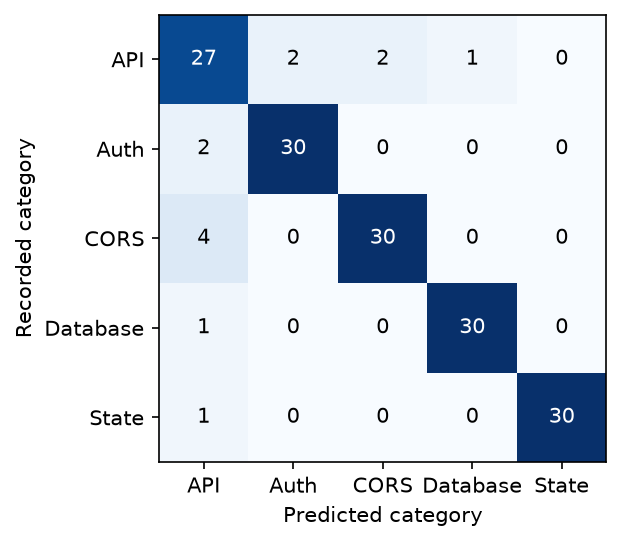

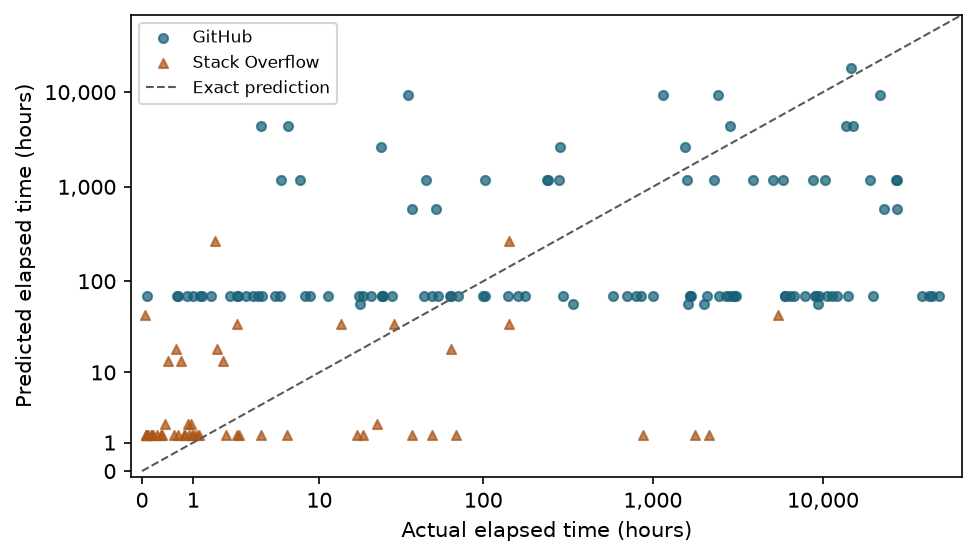

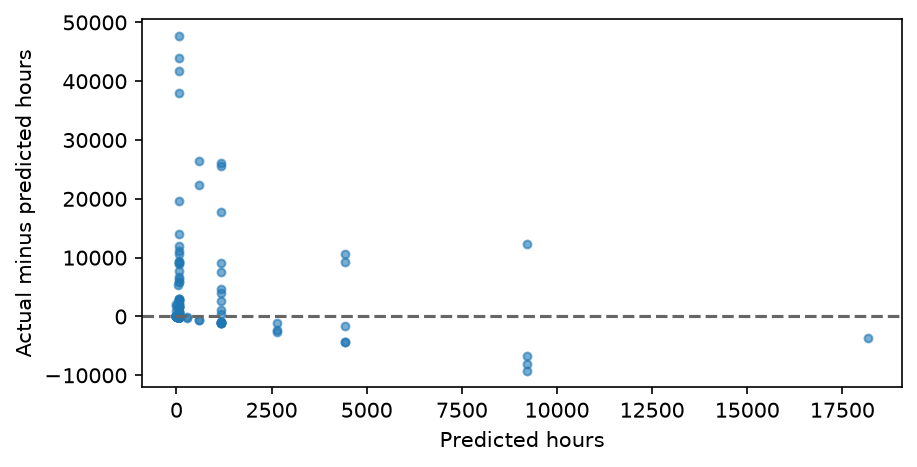

In [7]:
short_labels=["API", "Auth", "CORS", "Database", "State"]
assert classes == ["API_Error","Authentication","CORS_Error","Database_Connection","State_Management"]
cm = confusion_matrix(true_c,cpred[best_c],labels=classes)
fig_c, ax=plt.subplots(figsize=(6,3.5),layout="constrained")
ax.imshow(cm,cmap="Blues")
for (i,j),v in np.ndenumerate(cm):
    ax.text(j,i,str(v),ha="center",va="center",color="white" if v>cm.max()/2 else "black")
ax.set(xticks=range(5),xticklabels=short_labels,yticks=range(5),yticklabels=short_labels,
       xlabel="Predicted category",ylabel="Recorded category")
plt.show()
fig_r,ax=plt.subplots(figsize=(6.4,3.6),layout="constrained")
for source,color,marker in [("GitHub","#176178","o"),("Stack Overflow","#aa571a","^")]:
    mask=df.source.iloc[test].eq(source).to_numpy()
    ax.scatter(np.log1p(obs[mask]),np.log1p(pred[mask]),s=19,alpha=.72,label=source,c=color,marker=marker)
limit=max(np.log1p(obs).max(),np.log1p(pred).max())*1.03
ax.plot([0,limit],[0,limit],"--",color="0.35",linewidth=1,label="Exact prediction")
ticks=np.array([0,1,10,100,1000,10000,100000])
ticks=ticks[np.log1p(ticks)<=limit]
ax.set(xticks=np.log1p(ticks),xticklabels=[f"{v:,}" for v in ticks],yticks=np.log1p(ticks),
       yticklabels=[f"{v:,}" for v in ticks],xlim=(-.15,limit),ylim=(-.15,limit),
       xlabel="Actual elapsed time (hours)",ylabel="Predicted elapsed time (hours)")
ax.legend(fontsize=8,loc="upper left")
plt.show()
fig_res, ax=plt.subplots(figsize=(6,3),layout="constrained")
ax.scatter(pred, obs-pred, s=14, alpha=.6)
ax.axhline(0,ls="--",color="0.4")
ax.set(xlabel="Predicted hours",ylabel="Actual minus predicted hours")
plt.show()

## Sensitivity to repository overlap and source-specific durations
A fixed logistic model compares report-level and repository-disjoint folds on GitHub training records only. The regression comparator predicts the training mean within each source.

In [8]:
from sklearn.model_selection import GroupKFold, cross_val_predict

# Compare splits on the same GitHub training records with one fixed classifier.
gh = train[df.source.iloc[train].eq("GitHub").to_numpy()]
gh_target = df.Bug_Type.iloc[gh]
gh_groups = df.repository.iloc[gh]
diagnostic = Pipeline([("features", preprocessing(False)),
                       ("model", LogisticRegression(C=1, class_weight="balanced", max_iter=1500, random_state=SEED))])
ordinary_folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(gh, gh_target))
group_folds = list(GroupKFold(5).split(gh, gh_target, gh_groups))
print("GitHub training reports:", len(gh), "repositories:", gh_groups.nunique())
for title, folds in [("Report-stratified", ordinary_folds), ("Repository-disjoint", group_folds)]:
    with threadpool_limits(limits=1):
        gh_prediction = cross_val_predict(diagnostic, x.iloc[gh], gh_target, cv=folds)
    print(title, "pooled out-of-fold weighted F1:", round(f1_score(gh_target, gh_prediction, average="weighted"), 4))
# The source-only and global means below are calculated on training rows.
source_means = df.iloc[train].groupby("source").resolution_hours.mean()
by_source_prediction = df.source.iloc[test].map(source_means).to_numpy()
print("Source-specific training means:", source_means.to_dict())
print("Source-mean comparator:", error_summary(df.resolution_hours.iloc[test], by_source_prediction))


GitHub training reports: 440 repositories: 56
Report-stratified pooled out-of-fold weighted F1: 0.8177
Repository-disjoint pooled out-of-fold weighted F1: 0.7498
Source-specific training means: {'GitHub': 4517.930481590909, 'Stack Overflow': 267.92001650000003}
Source-mean comparator: {'MAE': 4462.9099150585225, 'MSE': 65730051.43704834, 'RMSE': 8107.4071957098795, 'R2': 0.07163407427637525}
